In [74]:
!pip install kagglehub[pandas-datasets]

In [75]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import kagglehub
from kagglehub import KaggleDatasetAdapter

In [76]:
file_path = "Wind Farm A/comma_event_info.csv"
events = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "azizkasimov/wind-turbine-scada-data-for-early-fault-detection",
    file_path,
)

file_path = "Wind Farm A/comma_feature_description.csv"
features = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "azizkasimov/wind-turbine-scada-data-for-early-fault-detection",
    file_path,
)

events.head()

/tmp/ipykernel_536/4114875831.py:2: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  events = kagglehub.load_dataset(


Using Colab cache for faster access to the 'wind-turbine-scada-data-for-early-fault-detection' dataset.


/tmp/ipykernel_536/4114875831.py:9: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  features = kagglehub.load_dataset(


Using Colab cache for faster access to the 'wind-turbine-scada-data-for-early-fault-detection' dataset.


,event_id,event_label,event_start,event_start_id,event_end,event_end_id,event_description
0,68,anomaly,2015-07-29 13:20:00,52063,2015-08-12 13:10:00,54076,Transformer failure
1,22,anomaly,2021-08-11 09:50:00,51888,2021-08-18 10:00:00,52892,Hydraulic group
2,72,anomaly,2021-10-09 08:40:00,52497,2021-10-16 08:40:00,53505,Gearbox failure
3,73,anomaly,2023-06-09 11:40:00,52745,2023-06-16 11:40:00,53753,Hydraulic group
4,0,anomaly,2022-08-05 06:10:00,52436,2022-08-19 06:10:00,54447,Generator bearing failure


In [77]:
features.head()

,sensor_name,statistics_type,description,unit,is_angle,is_counter
0,sensor_0,average,Ambient temperature,�C,False,False
1,sensor_1,average,Wind absolute direction,�,True,False
2,sensor_2,average,Wind relative direction,�,True,False
3,wind_speed_3,"maximum,minimum,average,std_dev",Windspeed,m/s,False,False
4,wind_speed_4,average,Estimated windspeed,m/s,False,False


In [78]:
cols_to_keep = [
    "id", "asset_id", "time_stamp", "train_test", "status_type_id",
    "wind_speed_3_avg", "sensor_0_avg", "sensor_1_avg",
    "sensor_11_avg", "sensor_43_avg", "sensor_50"
]

all_dfs = []
for eid in events["event_id"]:
    file_path = f"Wind Farm A/datasets/comma_{eid}.csv"
    temp = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        "azizkasimov/wind-turbine-scada-data-for-early-fault-detection",
        file_path,
    )
    temp = temp[cols_to_keep].copy()
    temp["event_id"] = eid
    all_dfs.append(temp)

df = pd.concat(all_dfs, ignore_index=True)
df = df[[
    "id", "event_id", "asset_id", "time_stamp", "train_test", "status_type_id",
    "wind_speed_3_avg", "sensor_0_avg", "sensor_1_avg",
    "sensor_11_avg", "sensor_43_avg", "sensor_50"
]]
df.head()

/tmp/ipykernel_536/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 33.9M/33.9M [00:01<00:00, 34.0MB/s]
/tmp/ipykernel_536/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 33.1M/33.1M [00:01<00:00, 33.2MB/s]
/tmp/ipykernel_536/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 33.8M/33.8M [00:01<00:00, 32.0MB/s]
/tmp/ipykernel_536/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


Using Colab cache for faster access to the 'wind-turbine-scada-data-for-early-fault-detection' dataset.


/tmp/ipykernel_536/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


... (28 outputs left out)

Using Colab cache for faster access to the 'wind-turbine-scada-data-for-early-fault-detection' dataset.


/tmp/ipykernel_536/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 34.0M/34.0M [00:01<00:00, 29.2MB/s]


,id,event_id,asset_id,time_stamp,train_test,status_type_id,wind_speed_3_avg,sensor_0_avg,sensor_1_avg,sensor_11_avg,sensor_43_avg,sensor_50
0,0,68,11,2014-07-29 13:20:00,train,5,3.9,31.0,152.0,40.0,38.0,-1185.0
1,1,68,11,2014-07-29 13:30:00,train,5,6.0,31.0,86.1,40.0,38.0,-1050.0
2,2,68,11,2014-07-29 13:40:00,train,5,6.3,31.0,115.2,39.0,38.0,-1043.0
3,3,68,11,2014-07-29 13:50:00,train,0,6.0,32.0,129.3,43.0,37.0,40124.0
4,4,68,11,2014-07-29 14:00:00,train,0,7.1,32.0,137.7,49.0,36.0,99360.0


In [79]:
Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)

df.to_csv("data/raw/scada.csv", index=False)
events.to_csv("data/raw/events.csv", index=False)
features.to_csv("data/raw/features.csv", index=False)

In [80]:
df.shape

(1196747, 12)

In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1196747 entries, 0 to 1196746
Data columns (total 12 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1196747 non-null  int64  
 1   event_id          1196747 non-null  int64  
 2   asset_id          1196747 non-null  int64  
 3   time_stamp        1196747 non-null  object 
 4   train_test        1196747 non-null  object 
 5   status_type_id    1196747 non-null  int64  
 6   wind_speed_3_avg  1196747 non-null  float64
 7   sensor_0_avg      1196747 non-null  float64
 8   sensor_1_avg      1196747 non-null  float64
 9   sensor_11_avg     1196747 non-null  float64
 10  sensor_43_avg     1196747 non-null  float64
 11  sensor_50         1196747 non-null  float64
dtypes: float64(6), int64(4), object(2)
memory usage: 109.6+ MB


In [82]:
df.describe()

,id,event_id,asset_id,status_type_id,wind_speed_3_avg,sensor_0_avg,sensor_1_avg,sensor_11_avg,sensor_43_avg,sensor_50
count,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06
mean,2.720275e+04,4.080538e+01,1.042951e+01,1.194069e+00,6.201962e+00,1.995072e+01,1.708527e+02,5.162426e+01,3.010808e+01,9.304541e+04
std,1.571098e+04,2.719184e+01,6.796280e+00,2.092604e+00,3.730365e+00,5.555743e+00,9.258916e+01,1.024465e+01,5.402276e+00,1.135679e+05
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e-01,4.000000e+00,0.000000e+00,1.500000e+01,1.500000e+01,-5.367000e+03
25%,1.359900e+04,1.700000e+01,1.000000e+01,0.000000e+00,3.200000e+00,1.600000e+01,9.790000e+01,4.400000e+01,2.600000e+01,-5.610000e+02
50%,2.719800e+04,3.800000e+01,1.100000e+01,0.000000e+00,5.500000e+00,1.900000e+01,1.294000e+02,5.300000e+01,3.000000e+01,3.882700e+04
75%,4.079800e+04,6.900000e+01,1.300000e+01,0.000000e+00,8.500000e+00,2.400000e+01,2.601000e+02,6.000000e+01,3.400000e+01,1.611880e+05
max,5.615700e+04,9.200000e+01,2.100000e+01,5.000000e+00,2.660000e+01,4.100000e+01,3.590000e+02,7.200000e+01,5.100000e+01,3.712560e+05


In [83]:
df.isnull().sum()

,0
id,0
event_id,0
asset_id,0
time_stamp,0
train_test,0
status_type_id,0
wind_speed_3_avg,0
sensor_0_avg,0
sensor_1_avg,0
sensor_11_avg,0


In [84]:
events.isnull().sum()

,0
event_id,0
event_label,0
event_start,0
event_start_id,0
event_end,0
event_end_id,0
event_description,11


In [85]:
events["event_description"] = events["event_description"].fillna("Normal")
events.isnull().sum()

,0
event_id,0
event_label,0
event_start,0
event_start_id,0
event_end,0
event_end_id,0
event_description,0


In [86]:
df.duplicated().sum()

np.int64(0)

In [87]:
df = df.rename(columns={
    "wind_speed_3_avg": "wind_speed",
    "sensor_0_avg": "ambient_temp",
    "sensor_1_avg": "wind_direction",
    "sensor_11_avg": "gearbox_temp",
    "sensor_43_avg": "nacelle_temp",
    "sensor_50": "power_output"
})

df["time_stamp"] = pd.to_datetime(df["time_stamp"])
events["event_start"] = pd.to_datetime(events["event_start"])
events["event_end"] = pd.to_datetime(events["event_end"])

df.dtypes

,0
id,int64
event_id,int64
asset_id,int64
time_stamp,datetime64[ns]
train_test,object
status_type_id,int64
wind_speed,float64
ambient_temp,float64
wind_direction,float64
gearbox_temp,float64


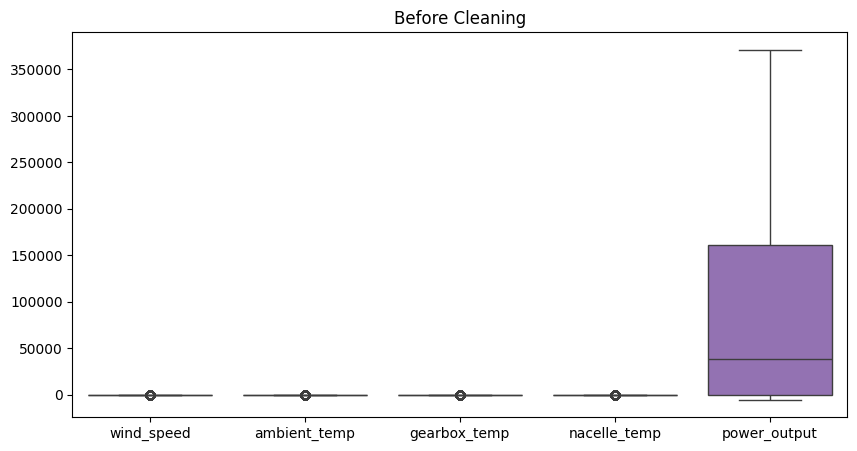

In [88]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[["wind_speed", "ambient_temp", "gearbox_temp", "nacelle_temp", "power_output"]])
plt.title("Before Cleaning")
plt.show()

In [89]:
Q1 = df["wind_speed"].quantile(0.25)
Q3 = df["wind_speed"].quantile(0.75)
IQR = Q3 - Q1
df["wind_speed"] = df["wind_speed"].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

Q1 = df["power_output"].quantile(0.25)
Q3 = df["power_output"].quantile(0.75)
IQR = Q3 - Q1
df["power_output"] = df["power_output"].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

df.describe()

,id,event_id,asset_id,time_stamp,status_type_id,wind_speed,ambient_temp,wind_direction,gearbox_temp,nacelle_temp,power_output
count,1.196747e+06,1.196747e+06,1.196747e+06,1196747,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06
mean,2.720275e+04,4.080538e+01,1.042951e+01,2020-05-16 16:36:39.680968704,1.194069e+00,6.179320e+00,1.995072e+01,1.708527e+02,5.162426e+01,3.010808e+01,9.304541e+04
min,0.000000e+00,0.000000e+00,0.000000e+00,2013-10-10 08:40:00,0.000000e+00,4.000000e-01,4.000000e+00,0.000000e+00,1.500000e+01,1.500000e+01,-5.367000e+03
25%,1.359900e+04,1.700000e+01,1.000000e+01,2019-06-17 15:40:00,0.000000e+00,3.200000e+00,1.600000e+01,9.790000e+01,4.400000e+01,2.600000e+01,-5.610000e+02
50%,2.719800e+04,3.800000e+01,1.100000e+01,2021-04-13 08:40:00,0.000000e+00,5.500000e+00,1.900000e+01,1.294000e+02,5.300000e+01,3.000000e+01,3.882700e+04
75%,4.079800e+04,6.900000e+01,1.300000e+01,2022-08-18 15:10:00,0.000000e+00,8.500000e+00,2.400000e+01,2.601000e+02,6.000000e+01,3.400000e+01,1.611880e+05
max,5.615700e+04,9.200000e+01,2.100000e+01,2023-09-20 00:50:00,5.000000e+00,1.645000e+01,4.100000e+01,3.590000e+02,7.200000e+01,5.100000e+01,3.712560e+05
std,1.571098e+04,2.719184e+01,6.796280e+00,NaN,2.092604e+00,3.657499e+00,5.555743e+00,9.258916e+01,1.024465e+01,5.402276e+00,1.135679e+05


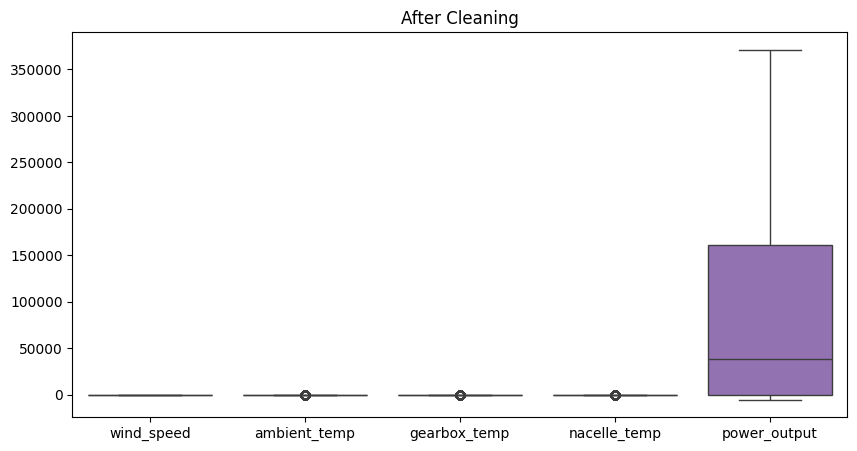

In [90]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[["wind_speed", "ambient_temp", "gearbox_temp", "nacelle_temp", "power_output"]])
plt.title("After Cleaning")
plt.show()

In [91]:
df["time_stamp"] = df["time_stamp"].astype(str)
events["event_start"] = events["event_start"].astype(str)
events["event_end"] = events["event_end"].astype(str)

df.to_csv("data/processed/scada_clean.csv", index=False)
events.to_csv("data/processed/events_clean.csv", index=False)
features.to_csv("data/processed/features_clean.csv", index=False)

In [92]:
dic = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Description": [
        "Row ID",
        "Event ID",
        "Asset ID",
        "Timestamp",
        "Train or Prediction",
        "Turbine Status ID",
        "Wind Speed",
        "Ambient Temperature",
        "Wind Direction",
        "Gearbox Temperature",
        "Nacelle Temperature",
        "Power Output"
    ]
})
dic.to_csv("data/processed/dic.csv", index=False)
dic

,Column,Data_Type,Description
0,id,int64,Row ID
1,event_id,int64,Event ID
2,asset_id,int64,Turbine Asset ID
3,time_stamp,object,Reading Timestamp
4,train_test,object,Train or Prediction Split
5,status_type_id,int64,Turbine Status ID
6,wind_speed,float64,Wind Speed
7,ambient_temp,float64,Ambient Temperature
8,wind_direction,float64,Wind Direction
9,gearbox_temp,float64,Gearbox Temperature


In [93]:
schema_sql = """
DROP TABLE IF EXISTS scada_readings;
DROP TABLE IF EXISTS events;
DROP TABLE IF EXISTS features;
DROP TABLE IF EXISTS status_types;

CREATE TABLE status_types (
    status_type_id INTEGER PRIMARY KEY,
    status_name TEXT,
    considered_normal INTEGER
);

CREATE TABLE events (
    event_id INTEGER PRIMARY KEY,
    event_label TEXT,
    event_start TEXT,
    event_start_id INTEGER,
    event_end TEXT,
    event_end_id INTEGER,
    event_description TEXT
);

CREATE TABLE features (
    sensor_name TEXT,
    statistics_type TEXT,
    description TEXT,
    unit TEXT,
    is_angle INTEGER,
    is_counter INTEGER
);

CREATE TABLE scada_readings (
    id INTEGER,
    event_id INTEGER,
    asset_id INTEGER,
    time_stamp TEXT,
    train_test TEXT,
    status_type_id INTEGER,
    wind_speed REAL,
    ambient_temp REAL,
    wind_direction REAL,
    gearbox_temp REAL,
    nacelle_temp REAL,
    power_output REAL,
    FOREIGN KEY (event_id) REFERENCES events(event_id),
    FOREIGN KEY (status_type_id) REFERENCES status_types(status_type_id)
);
"""

Path("schema.sql").write_text(schema_sql.strip())

1049

In [94]:
conn = sqlite3.connect("wind_turbine.sqlite")
conn.executescript(Path("schema.sql").read_text())

status_types = pd.DataFrame({
    "status_type_id": [0, 1, 2, 3, 4, 5],
    "status_name": ["Normal", "Derated", "Idling", "Service", "Downtime", "Other"],
    "considered_normal": [1, 0, 1, 0, 0, 0]
})

status_types.to_sql("status_types", conn, if_exists="replace", index=False)
events.to_sql("events", conn, if_exists="replace", index=False)
features.to_sql("features", conn, if_exists="replace", index=False)
df.to_sql("scada_readings", conn, if_exists="replace", index=False)

conn.commit()

In [95]:
pd.read_sql("SELECT * FROM status_types;", conn)

,status_type_id,status_name,considered_normal
0,0,Normal,1
1,1,Derated,0
2,2,Idling,1
3,3,Service,0
4,4,Downtime,0
5,5,Other,0


In [96]:
pd.read_sql("SELECT * FROM events LIMIT 10;", conn)

,event_id,event_label,event_start,event_start_id,event_end,event_end_id,event_description
0,68,anomaly,2015-07-29 13:20:00,52063,2015-08-12 13:10:00,54076,Transformer failure
1,22,anomaly,2021-08-11 09:50:00,51888,2021-08-18 10:00:00,52892,Hydraulic group
2,72,anomaly,2021-10-09 08:40:00,52497,2021-10-16 08:40:00,53505,Gearbox failure
3,73,anomaly,2023-06-09 11:40:00,52745,2023-06-16 11:40:00,53753,Hydraulic group
4,0,anomaly,2022-08-05 06:10:00,52436,2022-08-19 06:10:00,54447,Generator bearing failure
5,26,anomaly,2020-10-11 10:20:00,52261,2020-10-18 10:20:00,53269,Hydraulic group
6,40,anomaly,2022-12-24 00:00:00,51363,2023-01-24 13:00:00,55870,Generator bearing failure
7,42,anomaly,2023-09-08 15:50:00,52303,2023-09-15 15:50:00,53309,Hydraulic group
8,10,anomaly,2014-10-12 08:40:00,52611,2014-10-19 08:40:00,53591,Gearbox failure
9,45,anomaly,2020-04-18 18:10:00,52731,2020-04-25 18:10:00,53738,Hydraulic group


In [97]:
pd.read_sql("SELECT * FROM features LIMIT 10;", conn)

,sensor_name,statistics_type,description,unit,is_angle,is_counter
0,sensor_0,average,Ambient temperature,�C,0,0
1,sensor_1,average,Wind absolute direction,�,1,0
2,sensor_2,average,Wind relative direction,�,1,0
3,wind_speed_3,"maximum,minimum,average,std_dev",Windspeed,m/s,0,0
4,wind_speed_4,average,Estimated windspeed,m/s,0,0
5,sensor_5,"maximum,minimum,std_dev,average",Pitch angle,�,1,0
6,sensor_6,average,Temperature in the hub controller,�C,0,0
7,sensor_7,average,Temperature in the top nacelle controller,�C,0,0
8,sensor_8,average,Temperature in the choke coils on the VCS-section,�C,0,0
9,sensor_9,average,Temperature on the VCP-board,�C,0,0


In [98]:
pd.read_sql("SELECT * FROM scada_readings LIMIT 10;", conn)

,id,event_id,asset_id,time_stamp,train_test,status_type_id,wind_speed,ambient_temp,wind_direction,gearbox_temp,nacelle_temp,power_output
0,0,68,11,2014-07-29 13:20:00,train,5,3.9,31.0,152.0,40.0,38.0,-1185.0
1,1,68,11,2014-07-29 13:30:00,train,5,6.0,31.0,86.1,40.0,38.0,-1050.0
2,2,68,11,2014-07-29 13:40:00,train,5,6.3,31.0,115.2,39.0,38.0,-1043.0
3,3,68,11,2014-07-29 13:50:00,train,0,6.0,32.0,129.3,43.0,37.0,40124.0
4,4,68,11,2014-07-29 14:00:00,train,0,7.1,32.0,137.7,49.0,36.0,99360.0
5,5,68,11,2014-07-29 14:10:00,train,0,8.1,32.0,123.7,52.0,36.0,140370.0
6,6,68,11,2014-07-29 14:20:00,train,0,7.5,32.0,114.2,53.0,36.0,115325.0
7,7,68,11,2014-07-29 14:30:00,train,0,8.0,32.0,137.2,55.0,36.0,134797.0
8,8,68,11,2014-07-29 14:40:00,train,0,8.4,32.0,132.9,57.0,37.0,156685.0
9,9,68,11,2014-07-29 14:50:00,train,0,9.3,32.0,129.4,58.0,37.0,193997.0


In [99]:
pd.read_sql("""
SELECT event_label, COUNT(*) AS total_events
FROM events
GROUP BY event_label;
""", conn)

,event_label,total_events
0,anomaly,11
1,normal,11


In [100]:
pd.read_sql("""
SELECT event_description, COUNT(*) AS total_events
FROM events
GROUP BY event_description
ORDER BY total_events DESC;
""", conn)

,event_description,total_events
0,Normal,11
1,Hydraulic group,6
2,Generator bearing failure,2
3,Gearbox failure,2
4,Transformer failure,1


In [101]:
pd.read_sql("""
SELECT s.status_type_id, st.status_name, COUNT(*) AS total_readings
FROM scada_readings s
JOIN status_types st ON s.status_type_id = st.status_type_id
GROUP BY s.status_type_id, st.status_name
ORDER BY total_readings DESC;
""", conn)

,status_type_id,status_name,total_readings
0,0,Normal,898672
1,5,Other,260387
2,3,Service,23689
3,4,Downtime,13999


In [102]:
pd.read_sql("""
SELECT asset_id,
       ROUND(AVG(wind_speed), 2) AS avg_wind_speed,
       ROUND(MIN(wind_speed), 2) AS min_wind_speed,
       ROUND(MAX(wind_speed), 2) AS max_wind_speed,
       ROUND(AVG(power_output), 2) AS avg_power,
       ROUND(MAX(power_output), 2) AS max_power
FROM scada_readings
WHERE status_type_id = 0
GROUP BY asset_id
ORDER BY avg_power DESC;
""", conn)

,asset_id,avg_wind_speed,min_wind_speed,max_wind_speed,avg_power,max_power
0,0,7.05,0.5,16.45,121235.20,334355.0
1,13,6.90,0.4,16.45,120142.22,334277.0
2,21,6.80,0.4,16.45,118794.98,334398.0
3,11,6.90,0.4,16.45,115781.84,333853.0
4,10,6.83,0.4,16.45,112546.45,334458.0


In [103]:
pd.read_sql("""
SELECT e.event_label,
       COUNT(*) AS total_readings,
       ROUND(AVG(s.ambient_temp), 2) AS avg_ambient_temp,
       ROUND(AVG(s.nacelle_temp), 2) AS avg_nacelle_temp,
       ROUND(AVG(s.gearbox_temp), 2) AS avg_gearbox_temp
FROM scada_readings s
JOIN events e ON s.event_id = e.event_id
GROUP BY e.event_label;
""", conn)

,event_label,total_readings,avg_ambient_temp,avg_nacelle_temp,avg_gearbox_temp
0,anomaly,595353,20.03,30.25,51.62
1,normal,601394,19.88,29.97,51.63


In [104]:
pd.read_sql("""
SELECT e.event_description,
       ROUND(AVG(s.gearbox_temp), 2) AS avg_gearbox_temp,
       ROUND(MAX(s.gearbox_temp), 2) AS max_gearbox_temp
FROM scada_readings s
JOIN events e ON s.event_id = e.event_id
GROUP BY e.event_description
ORDER BY avg_gearbox_temp DESC;
""", conn)

,event_description,avg_gearbox_temp,max_gearbox_temp
0,Hydraulic group,52.44,72.0
1,Normal,51.63,72.0
2,Transformer failure,51.04,68.0
3,Gearbox failure,50.93,72.0
4,Generator bearing failure,50.19,71.0


In [105]:
pd.read_sql("""
SELECT
    CASE
        WHEN wind_speed < 4 THEN 'Low Wind'
        WHEN wind_speed BETWEEN 4 AND 10 THEN 'Medium Wind'
        ELSE 'High Wind'
    END AS wind_band,
    COUNT(*) AS total_readings,
    ROUND(AVG(power_output), 2) AS avg_power,
    ROUND(AVG(gearbox_temp), 2) AS avg_gearbox_temp
FROM scada_readings
GROUP BY wind_band
ORDER BY avg_power DESC;
""", conn)

,wind_band,total_readings,avg_power,avg_gearbox_temp
0,High Wind,191476,292925.62,62.37
1,Medium Wind,598270,92255.35,55.53
2,Low Wind,407001,171.94,40.82


In [106]:
pd.read_sql("""
SELECT asset_id,
       COUNT(*) AS high_temp_readings,
       ROUND(AVG(gearbox_temp), 2) AS avg_gearbox_temp,
       ROUND(MAX(gearbox_temp), 2) AS max_gearbox_temp
FROM scada_readings
WHERE gearbox_temp > 60
GROUP BY asset_id
HAVING COUNT(*) >= 100
ORDER BY high_temp_readings DESC;
""", conn)

,asset_id,high_temp_readings,avg_gearbox_temp,max_gearbox_temp
0,13,83513,64.50,72.0
1,10,66524,63.67,72.0
2,21,50607,62.52,69.0
3,0,48502,62.19,68.0
4,11,36506,62.05,68.0


In [107]:
pd.read_sql("""
SELECT train_test,
       COUNT(*) AS total_readings,
       ROUND(AVG(wind_speed), 2) AS avg_wind_speed,
       ROUND(AVG(power_output), 2) AS avg_power
FROM scada_readings
GROUP BY train_test;
""", conn)

,train_test,total_readings,avg_wind_speed,avg_power
0,prediction,50593,6.39,98432.66
1,train,1146154,6.17,92807.61


In [108]:
pd.read_sql("""
SELECT strftime('%Y-%m', time_stamp) AS reading_month,
       COUNT(*) AS total_readings,
       ROUND(AVG(wind_speed), 2) AS avg_wind_speed,
       ROUND(AVG(power_output), 2) AS avg_power
FROM scada_readings
GROUP BY reading_month
ORDER BY reading_month
LIMIT 12;
""", conn)

,reading_month,total_readings,avg_wind_speed,avg_power
0,2013-10,3102,5.96,83365.79
1,2013-11,4313,5.12,63227.28
2,2013-12,4460,6.69,112446.98
3,2014-01,4421,4.50,31338.02
4,2014-02,4030,6.15,95569.16
5,2014-03,4458,6.17,97304.44
6,2014-04,4320,7.87,143517.87
7,2014-05,4464,6.77,111753.63
8,2014-06,4309,6.39,102201.41
9,2014-07,4671,5.36,65135.51
